[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/03-math-for-ai/notebooks/04-derivatives-and-gradient-descent.ipynb)

# 04 · Derivatives, gradients and gradient descent

**What you will learn**
- slope of a line, and the **derivative** as the slope of a curve at a point
- estimating a derivative with a tiny step (**numerical derivative**)
- **gradient descent** step by step, shown as a sequence of frames (a flip-book "animation")
- the effect of the **learning rate**
- gradient descent with two weights on a contour map
- **loss functions** (MSE, cross-entropy) and fitting a line from scratch

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)   # print numbers neatly
NAVY, TEAL, RED, ORANGE = "#1B263B", "#0F9D9A", "#D1495B", "#F28C28"   # course colours

## 1. Slope of a straight line

Slope = rise ÷ run: how much `y` goes up for one step right.

In [2]:
x1, y1 = 1, 3
x2, y2 = 4, 9
print("slope =", (y2 - y1) / (x2 - x1))

slope = 2.0


## 2. The slope of a curve at one point

For a curve, take a *tiny* step `h` and measure the change. As `h` shrinks, the estimate settles on the true slope. For f(x) = x², the slope at x = 3 is 6.

In [3]:
def f(x):
    return x ** 2

def numerical_derivative(func, x, h=1e-4):
    return (func(x + h) - func(x)) / h

for h in [1, 0.1, 0.01, 0.0001]:
    print(f"h = {h:<7} slope estimate = {numerical_derivative(f, 3, h):.4f}")

h = 1       slope estimate = 7.0000
h = 0.1     slope estimate = 6.1000
h = 0.01    slope estimate = 6.0100
h = 0.0001  slope estimate = 6.0001


## 3. Tangent lines

The **tangent line** touches the curve at one point with the curve's slope there. Negative slope = downhill to the right; zero = flat bottom; positive = uphill to the right.

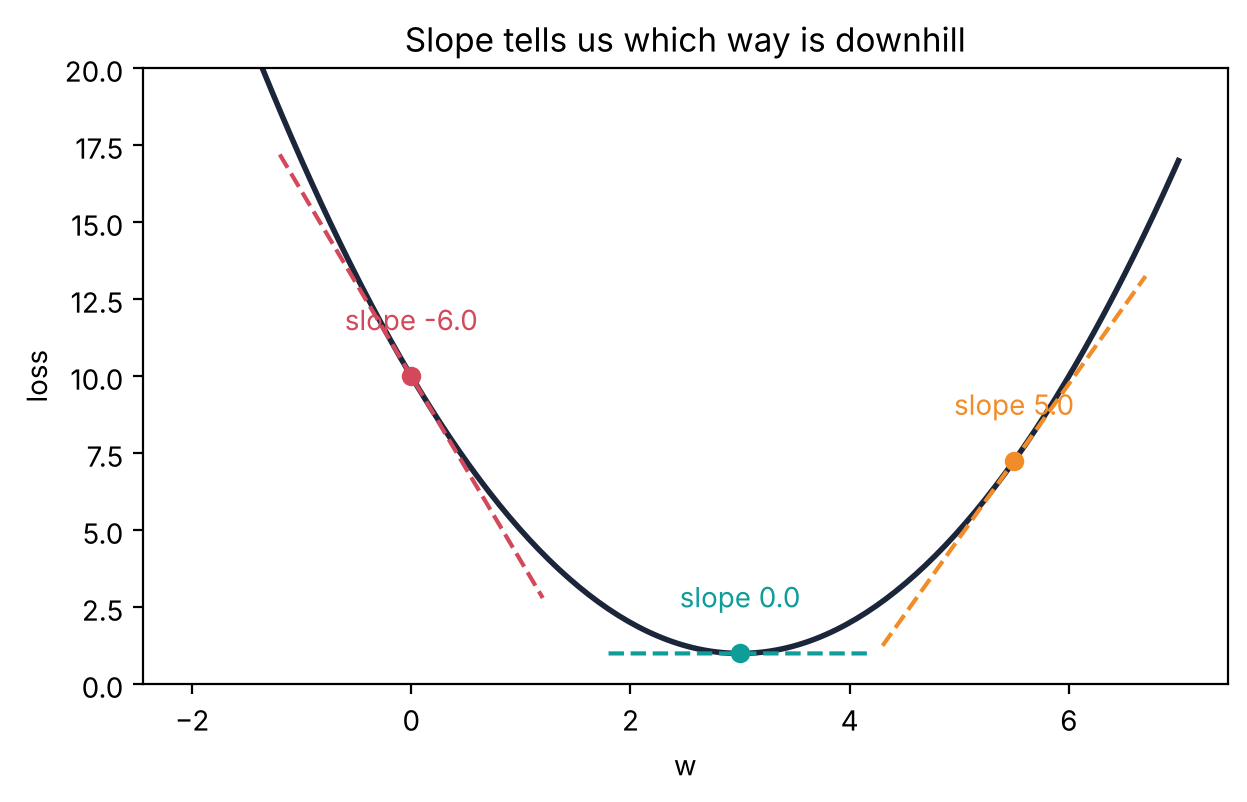

In [4]:
def loss(w):
    return (w - 3) ** 2 + 1

xs = np.linspace(-2, 7, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, loss(xs), color=NAVY, lw=2)
for w0, c in [(0, RED), (3, TEAL), (5.5, ORANGE)]:
    s = numerical_derivative(loss, w0)
    t = np.linspace(w0 - 1.2, w0 + 1.2, 10)
    ax.plot(t, loss(w0) + s * (t - w0), "--", color=c)
    ax.plot(w0, loss(w0), "o", color=c); ax.text(w0, loss(w0) + 1.5, f"slope {s:.1f}", color=c, ha="center")
ax.set_ylim(0, 20); ax.set_xlabel("w"); ax.set_ylabel("loss"); ax.set_title("Slope tells us which way is downhill")
plt.show()

## 4. Gradient descent, one step at a time

Rule: `new_w = w − learning_rate × slope`.
If the slope is negative, `− learning_rate × slope` is positive, so w moves right (downhill). If positive, w moves left. Start at w = −1 with learning rate 0.2.
The exact slope of `(w − 3)² + 1` is `2(w − 3)`; we use it directly here.

In [5]:
def slope(w):
    return 2 * (w - 3)

w, lr = -1.0, 0.2
history = [w]
for step in range(1, 11):
    w = w - lr * slope(w)
    history.append(w)
    print(f"step {step:2d}: w = {w:6.3f}   loss = {loss(w):6.3f}   slope = {slope(w):6.3f}")

step  1: w =  0.600   loss =  6.760   slope = -4.800
step  2: w =  1.560   loss =  3.074   slope = -2.880
step  3: w =  2.136   loss =  1.746   slope = -1.728
step  4: w =  2.482   loss =  1.269   slope = -1.037
step  5: w =  2.689   loss =  1.097   slope = -0.622
step  6: w =  2.813   loss =  1.035   slope = -0.373
step  7: w =  2.888   loss =  1.013   slope = -0.224
step  8: w =  2.933   loss =  1.005   slope = -0.134
step  9: w =  2.960   loss =  1.002   slope = -0.081
step 10: w =  2.976   loss =  1.001   slope = -0.048


## 5. The "animation": a sequence of frames

We draw one picture per step (the red dot is the current w, the orange dashes are the tangent, the arrow shows the next step) and save each as a PNG in `outputs/gd_frames/`. Shown together in a grid they read like a flip-book. Notice the steps shrink as the slope flattens.

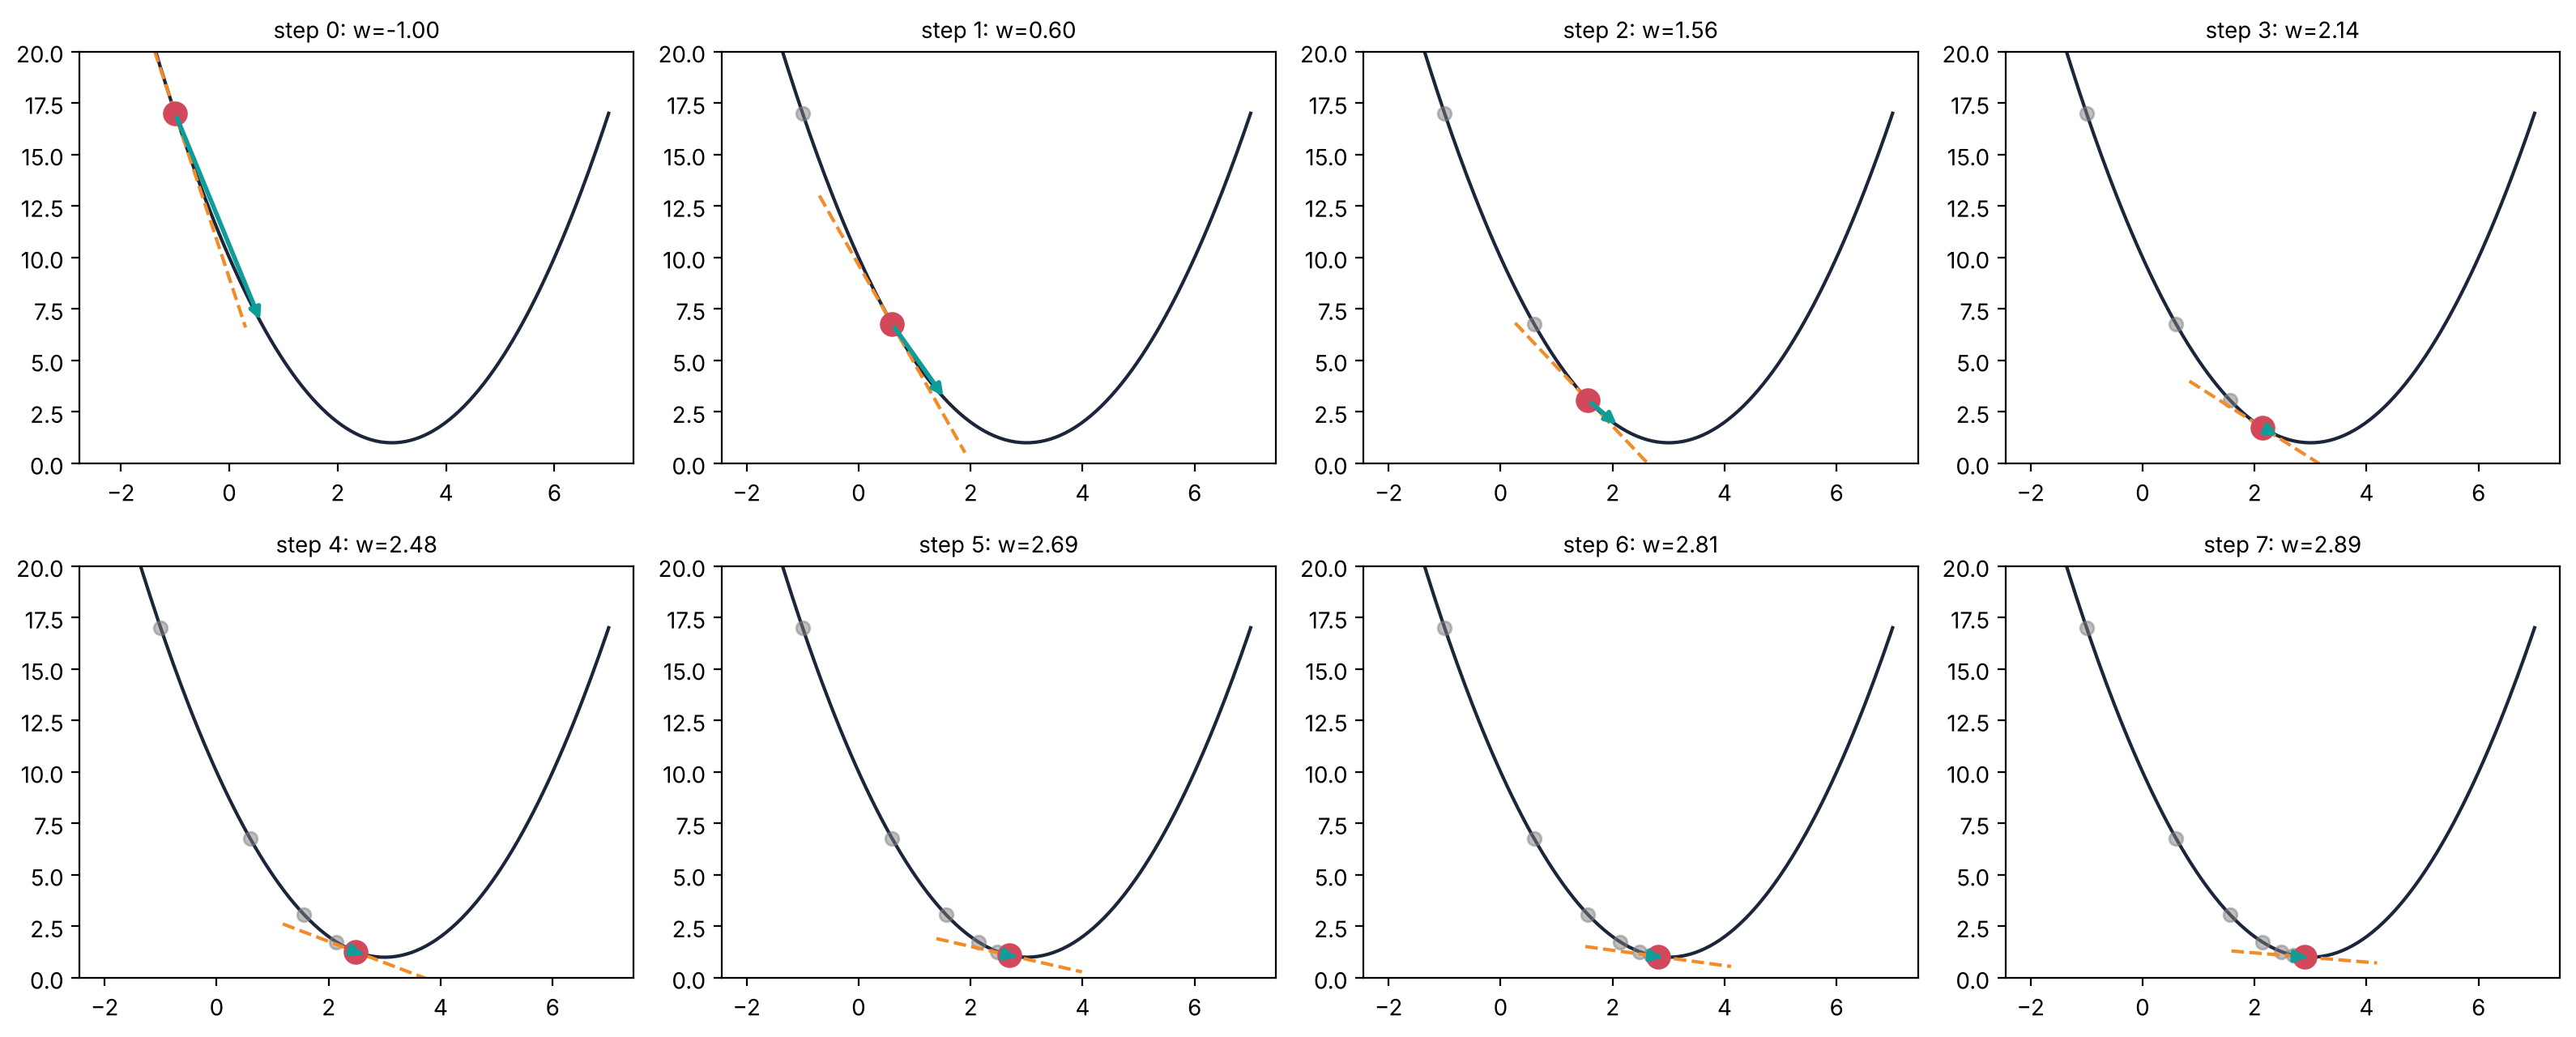

saved: ['frame_01.png', 'frame_02.png', 'frame_03.png', 'frame_04.png', 'frame_05.png', 'frame_06.png', 'frame_07.png', 'frame_08.png']


In [6]:
from pathlib import Path
frames_dir = Path("outputs/gd_frames")
frames_dir.mkdir(parents=True, exist_ok=True)

def draw_frame(ax, k):
    ax.plot(xs, loss(xs), color=NAVY)
    ax.plot(history[:k], [loss(h) for h in history[:k]], "o", color="grey", alpha=0.5)
    w = history[k]
    t = np.linspace(w - 1.3, w + 1.3, 10)
    ax.plot(t, loss(w) + slope(w) * (t - w), "--", color=ORANGE)
    ax.plot(w, loss(w), "o", color=RED, ms=10)
    ax.annotate("", xy=(history[k + 1], loss(history[k + 1])), xytext=(w, loss(w)),
                arrowprops=dict(arrowstyle="-|>", color=TEAL, lw=2))
    ax.set_ylim(0, 20); ax.set_title(f"step {k}: w={w:.2f}", fontsize=10)

for k in range(8):                                   # save each frame as its own image
    fig, ax = plt.subplots(figsize=(5, 3))
    draw_frame(ax, k)
    fig.savefig(frames_dir / f"frame_{k + 1:02d}.png", dpi=80, bbox_inches="tight")
    plt.close(fig)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))    # and show all 8 together
for k, ax in enumerate(axes.flat):
    draw_frame(ax, k)
plt.tight_layout(); plt.show()
print("saved:", sorted(p.name for p in frames_dir.iterdir()))

## 6. Learning rate: too small, about right, too large

Same start, three step sizes, 10 steps each. Too small crawls; too large overshoots and blows up (**divergence**).

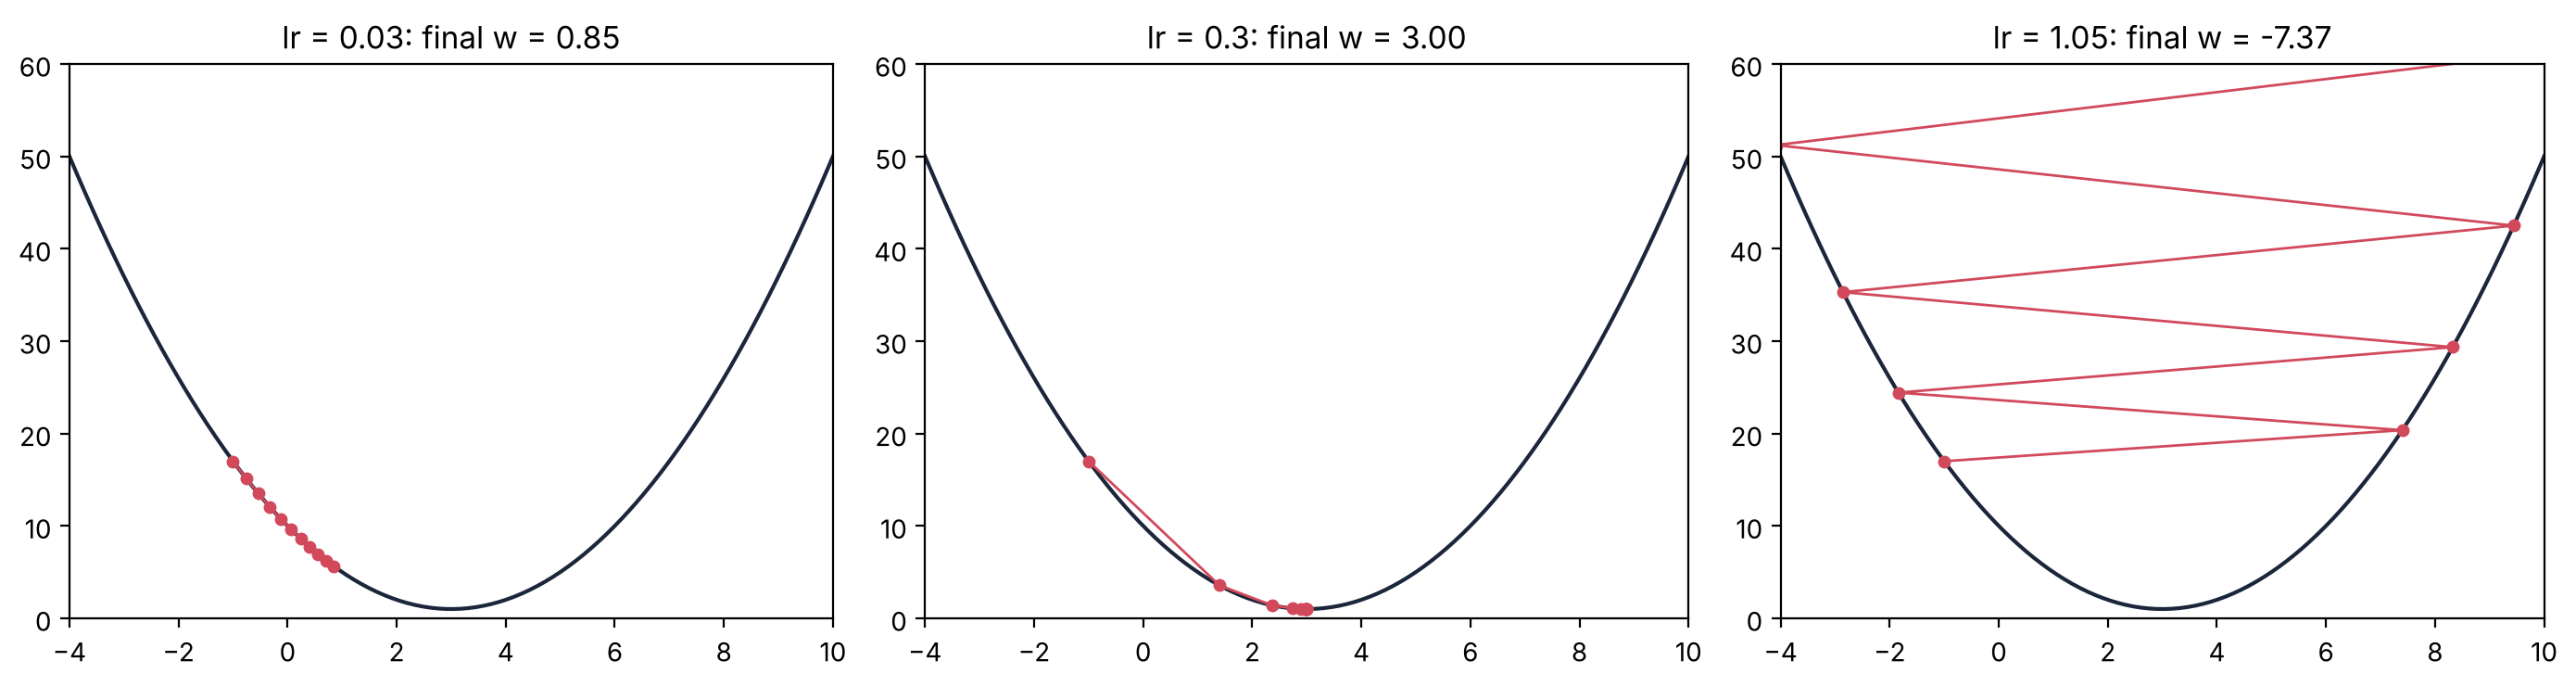

In [7]:
def run_gd(lr, w=-1.0, steps=10):
    path = [w]
    for _ in range(steps):
        w = w - lr * slope(w)
        path.append(w)
    return np.array(path)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, lr in zip(axes, [0.03, 0.3, 1.05]):
    p = run_gd(lr)
    ax.plot(np.linspace(-4, 10, 200), loss(np.linspace(-4, 10, 200)), color=NAVY)
    ax.plot(p, loss(p), "-o", color=RED, ms=4, lw=1)
    ax.set_xlim(-4, 10); ax.set_ylim(0, 60); ax.set_title(f"lr = {lr}: final w = {p[-1]:.2f}")
plt.tight_layout(); plt.show()

## 7. Two weights: walking down a bowl

Loss = w1² + 4·w2². The **gradient** is the list of both slopes: `[2·w1, 8·w2]`. Each step moves against it. The contour lines are like a hiking map: each line has equal loss.

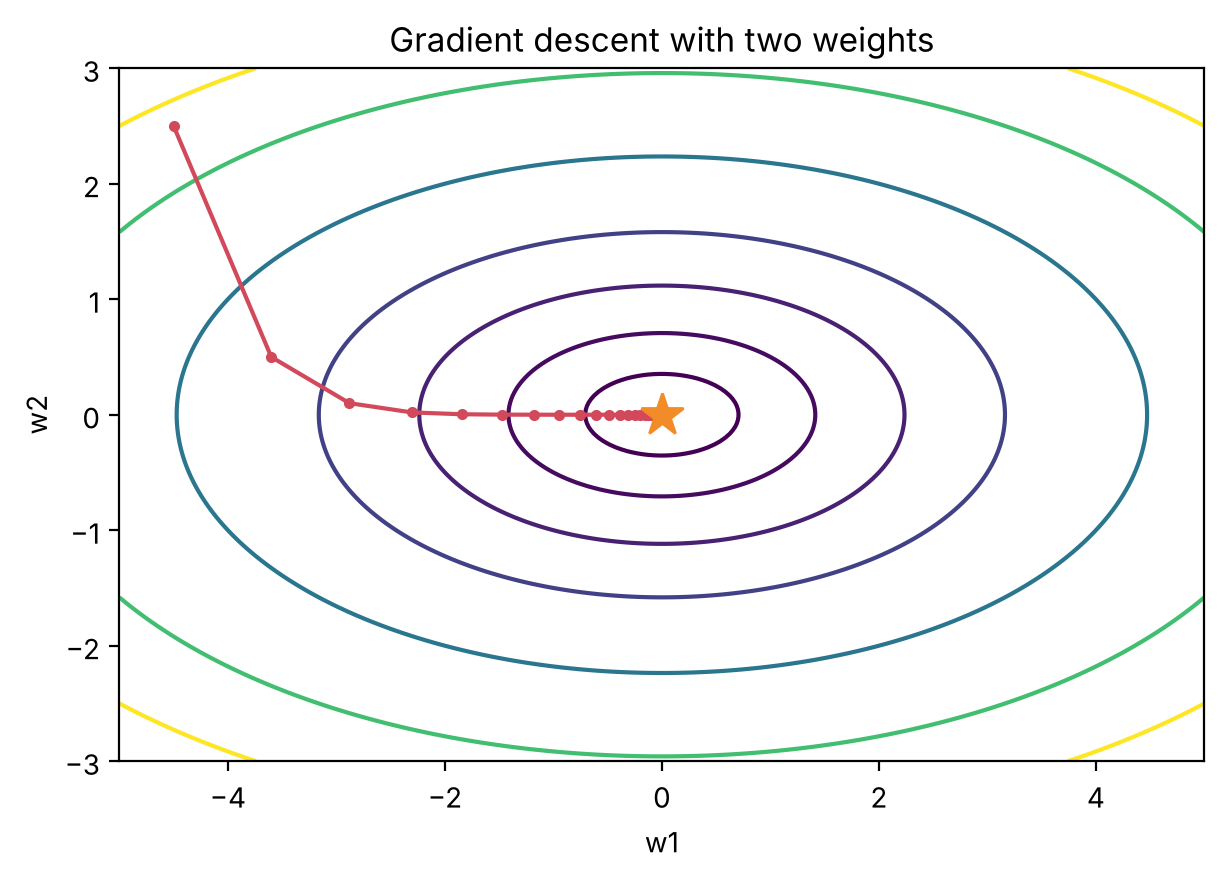

start loss: 45.25 | end loss: 0.00029


In [8]:
def loss2(w):
    return w[0] ** 2 + 4 * w[1] ** 2

def gradient2(w):
    return np.array([2 * w[0], 8 * w[1]])

w = np.array([-4.5, 2.5]); path = [w.copy()]
for _ in range(25):
    w = w - 0.1 * gradient2(w)
    path.append(w.copy())
path = np.array(path)

A, B = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3, 3, 200))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.contour(A, B, A ** 2 + 4 * B ** 2, levels=[0.5, 2, 5, 10, 20, 35, 50], cmap="viridis")
ax.plot(path[:, 0], path[:, 1], "-o", color=RED, ms=3)
ax.plot(0, 0, "*", color=ORANGE, ms=16)
ax.set_xlabel("w1"); ax.set_ylabel("w2"); ax.set_title("Gradient descent with two weights"); plt.show()
print("start loss:", loss2(path[0]), "| end loss:", round(loss2(path[-1]), 5))

## 8. Loss functions

- **MSE** (mean squared error) for numbers: average of (prediction − truth)².
- **Cross-entropy** for categories: −log(probability of the correct answer).

In [9]:
y_true = np.array([3.0, 5.0, 7.0])
good = np.array([3.1, 4.8, 7.2])
bad = np.array([1.0, 8.0, 4.0])
mse = lambda p, t: np.mean((p - t) ** 2)
print("MSE good predictions:", round(mse(good, y_true), 3))
print("MSE bad predictions: ", round(mse(bad, y_true), 3))
for p in [0.9, 0.5, 0.1, 0.01]:
    print(f"cross-entropy when correct answer had p={p}: {-np.log(p):.3f}")

MSE good predictions: 0.03
MSE bad predictions:  7.333
cross-entropy when correct answer had p=0.9: 0.105
cross-entropy when correct answer had p=0.5: 0.693
cross-entropy when correct answer had p=0.1: 2.303
cross-entropy when correct answer had p=0.01: 4.605


## 9. Machine learning in miniature: fit a line with gradient descent

Data roughly follows y = 2x + 1 plus noise. We learn `w` (slope) and `b` (intercept) from zero:
1. predict `w*x + b` · 2. error = prediction − y · 3. gradients of MSE: `dw = 2·mean(error·x)`, `db = 2·mean(error)` · 4. update both.

In [10]:
rng = np.random.default_rng(42)
x = np.linspace(0, 5, 20)
y = 2 * x + 1 + rng.normal(0, 0.8, x.size)

w, b, lr = 0.0, 0.0, 0.05
losses, snapshots = [], {}
for step in range(201):
    pred = w * x + b
    error = pred - y
    losses.append(np.mean(error ** 2))
    if step in (0, 3, 15, 200):
        snapshots[step] = (w, b)
    w -= lr * 2 * np.mean(error * x)
    b -= lr * 2 * np.mean(error)

print(f"learned: y = {w:.3f}x + {b:.3f}")
print("np.polyfit answer:", np.round(np.polyfit(x, y, 1), 3))

learned: y = 2.077x + 0.780
np.polyfit answer: [2.077 0.781]


Plot the line at a few steps, and the loss curve. The loss drops fast at first, then levels off.

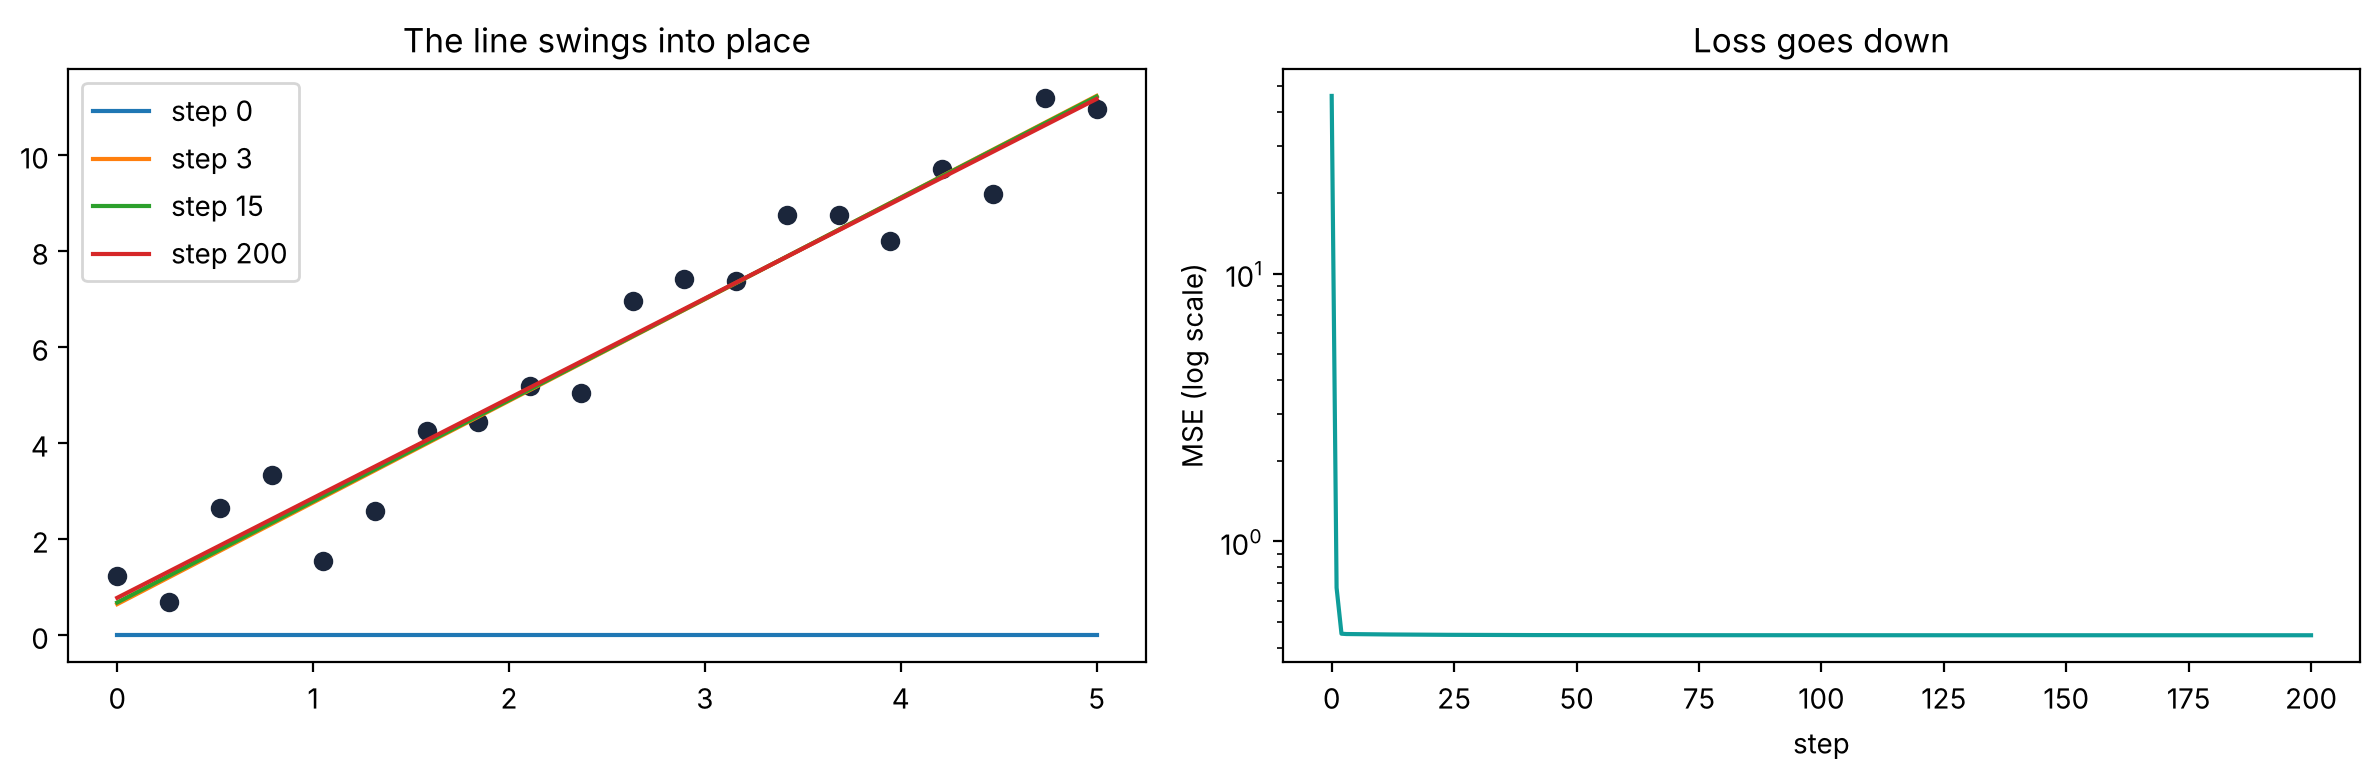

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(x, y, color=NAVY)
for step, (ww, bb) in snapshots.items():
    axes[0].plot(x, ww * x + bb, label=f"step {step}")
axes[0].legend(); axes[0].set_title("The line swings into place")
axes[1].plot(losses, color=TEAL); axes[1].set_yscale("log")
axes[1].set_xlabel("step"); axes[1].set_ylabel("MSE (log scale)"); axes[1].set_title("Loss goes down")
plt.tight_layout(); plt.show()

## Your turn
1. Rerun section 9 with `lr = 0.2`. What happens? Then try `lr = 0.01` for 200 steps. Which is closer to the polyfit answer?
2. Change the loss in section 4 to `(w + 2)**2` (and its slope to `2*(w + 2)`). Where does gradient descent end up?

## Recap
Derivative = slope at a point. Gradient = all the slopes. Gradient descent: step against the gradient, repeat. Learning rate = step size. Loss = one number for "how wrong". Together: training.